# Zadanie 1 — audyt danych i protokół (część 1)

**Projekt:** Klasyfikacja kategorii produktów na podstawie ich nazw.

Ten notebook wykonuje audyt zbioru **Product Classification and Clustering** (PriceRunner / UCI). Na tym etapie nie trenujemy modeli i nie tworzymy podziału. Podział grupowy po `Cluster ID` zostanie dodany po analizie wyników.

**Źródło:** https://archive.ics.uci.edu/dataset/837/product+classification+and+clustering

**Seed planowanego eksperymentu:** 42.

## 1. Wczytanie danych

Pobrany z UCI plik ZIP (`product+classification+and+clustering.zip`) należy umieścić **lokalnie** w folderze `data/`. Nie dodajemy pełnego zbioru do repozytorium GitHub.

Uwaga: w oryginalnym CSV niektóre nazwy kolumn mają spację na początku. Usuwamy te spacje z nazw kolumn (`str.strip()`).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
FILE_NAME = "product+classification+and+clustering.zip"

# Obsługuje uruchamianie z folderu repozytorium lub z notebooks/.
candidates = [Path("data") / FILE_NAME, Path("..") / "data" / FILE_NAME]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError(f"Umieść {FILE_NAME} w folderze data/ repozytorium.")

df = pd.read_csv(path, compression="zip")
df.columns = df.columns.str.strip()

print("Plik:", path)
print("Wymiary zbioru:", df.shape)
print("Kolumny:", df.columns.tolist())

Plik: ../data/product+classification+and+clustering.zip
Wymiary zbioru: (35311, 7)
Kolumny: ['Product ID', 'Product Title', 'Merchant ID', 'Cluster ID', 'Cluster Label', 'Category ID', 'Category Label']


## 2. Przykładowe rekordy

In [2]:
display(df[["Product ID", "Product Title", "Cluster ID", "Category Label"]].head(6))

,Product ID,Product Title,Cluster ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,1,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,1,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,1,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,1,Mobile Phones
5,6,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,1,Mobile Phones


## 3. Rozkład klas i niezależne jednostki

Jednym przykładem jest oferta (`Product ID`). Jednostką generalizacji jest **produkt** (`Cluster ID`). Wiele ofert może odnosić się do tego samego produktu.

In [3]:
print("Liczba ofert:", len(df))
print("Liczba unikalnych Product ID:", df["Product ID"].nunique())
print("Liczba produktów (Cluster ID):", df["Cluster ID"].nunique())
print("Liczba sprzedawców:", df["Merchant ID"].nunique())

class_table = (
    df.groupby("Category Label")
    .agg(liczba_ofert=("Product ID", "size"), liczba_produktow=("Cluster ID", "nunique"))
    .sort_values("liczba_ofert", ascending=False)
)
class_table["udzial_ofert_%"] = (100 * class_table["liczba_ofert"] / len(df)).round(2)
display(class_table)

Liczba ofert: 35311
Liczba unikalnych Product ID: 35311
Liczba produktów (Cluster ID): 13233
Liczba sprzedawców: 306


,liczba_ofert,liczba_produktow,udzial_ofert_%
Category Label,,,
Fridge Freezers,5501,1998,15.58
Mobile Phones,4081,1704,11.56
Washing Machines,4044,1277,11.45
CPUs,3862,1975,10.94
Fridges,3584,1373,10.15
TVs,3564,1280,10.09
Dishwashers,3424,1368,9.70
Digital Cameras,2697,713,7.64
Microwaves,2342,785,6.63


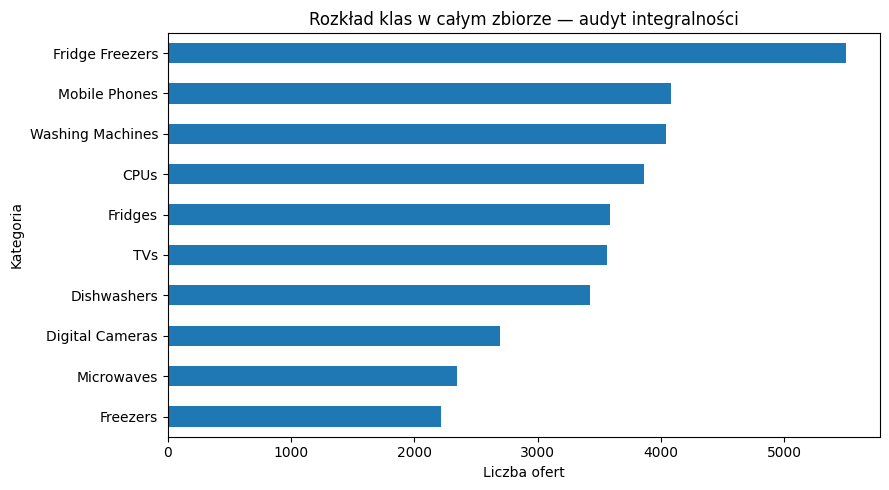

In [4]:
ax = class_table["liczba_ofert"].sort_values().plot.barh(figsize=(9, 5))
ax.set_xlabel("Liczba ofert")
ax.set_ylabel("Kategoria")
ax.set_title("Rozkład klas w całym zbiorze — audyt integralności")
plt.tight_layout()
plt.show()

## 4. Braki danych, duplikaty i spójność etykiet

Sprawdzamy duplikaty tytułów oraz to, czy jeden `Cluster ID` ma zawsze jedną kategorię. **Duplikaty tytułów w różnych klastrach** są potencjalnym źródłem wycieku informacji mimo podziału grupowego.

In [5]:
print("Brakujące wartości w kolumnach:")
display(df.isna().sum().rename("braki").to_frame())
print("Puste tytuły:", df["Product Title"].astype(str).str.strip().eq("").sum())
print("Duplikaty identyfikatorów Product ID:", df["Product ID"].duplicated().sum())
print("Powtórzenia dokładnych tytułów ponad pierwsze wystąpienie:", df["Product Title"].duplicated().sum())

clusters_per_title = df.groupby("Product Title")["Cluster ID"].nunique()
print("Liczba tytułów występujących w różnych Cluster ID:", (clusters_per_title > 1).sum())

categories_per_title = df.groupby("Product Title")["Category Label"].nunique()
print("Liczba identycznych tytułów z różnymi etykietami:", (categories_per_title > 1).sum())

categories_per_cluster = df.groupby("Cluster ID")["Category Label"].nunique()
print("Liczba Cluster ID z więcej niż jedną kategorią:", (categories_per_cluster > 1).sum())
assert categories_per_cluster.max() == 1, "Uwaga: sprzeczne etykiety w Cluster ID!"

# Przykłady potencjalnego błędnego oznaczenia, bez automatycznego poprawiania etykiet.
ambiguous_titles = categories_per_title[categories_per_title > 1].index
cols = ["Product ID", "Product Title", "Cluster ID", "Cluster Label", "Category Label"]
display(df.loc[df["Product Title"].isin(ambiguous_titles), cols].sort_values("Product Title"))

Brakujące wartości w kolumnach:


,braki
Product ID,0
Product Title,0
Merchant ID,0
Cluster ID,0
Cluster Label,0
Category ID,0
Category Label,0


Puste tytuły: 0
Duplikaty identyfikatorów Product ID: 0
Powtórzenia dokładnych tytułów ponad pierwsze wystąpienie: 4318
Liczba tytułów występujących w różnych Cluster ID: 617
Liczba identycznych tytułów z różnymi etykietami: 2
Liczba Cluster ID z więcej niż jedną kategorią: 0


,Product ID,Product Title,Cluster ID,Cluster Label,Category Label
31700,43365,blomberg kgm9550 fridge freezer,46085,Blomberg KGM 9550 White,Fridge Freezers
35196,47235,blomberg kgm9550 fridge freezer,47395,Blomberg KGM9550 Stainless Steel,Fridges
23671,34378,bosch kur15a50gb integrated undercounter fridge,42819,Hotpoint WMUD962G,Washing Machines
31728,43394,bosch kur15a50gb integrated undercounter fridge,46113,Bosch KUR15A50GB Integrated,Fridges


## 5. Statystyki tekstu i wielkości klastrów

Tytuły są krótkimi tekstami. Liczby słów i znaków pomogą uzasadnić wybrane metody reprezentacji tekstu w kolejnych zadaniach.

In [6]:
stats = pd.DataFrame({
    "znaki": df["Product Title"].str.len(),
    "slowa": df["Product Title"].str.split().str.len(),
})
display(stats.describe().round(2))

cluster_sizes = df.groupby("Cluster ID").size()
print("Oferty na jeden produkt (Cluster ID):")
display(cluster_sizes.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

,znaki,slowa
count,35311.00,35311.00
mean,52.98,8.67
std,22.45,4.17
min,5.00,1.00
25%,38.00,6.00
50%,52.00,8.00
75%,65.00,11.00
max,200.00,37.00


Oferty na jeden produkt (Cluster ID):


count    13233.00
mean         2.67
std          2.47
min          1.00
50%          2.00
75%          3.00
90%          5.00
95%          8.00
99%         12.00
max         27.00
dtype: float64

## 6. Wnioski z audytu (do wykorzystania w README)

- Przykład: pojedyncza oferta produktu (`Product ID`). Jednostka generalizacji: unikalny produkt (`Cluster ID`).
- Oryginalne etykiety są w `Category Label`, nie tworzymy nowych klas.
- W analizie podziału konieczna jest kontrola rozdzielenia `Cluster ID` oraz dodatkowa kontrola identycznych tytułów w różnych klastrach.
- Rozkład kategorii nie jest równomierny, dlatego zaplanowano **macro-F1** jako metrykę główną.
- Przed treningiem modele i preprocessing będą dopasowywane tylko do danych treningowych.
- **Następny krok:** przygotowanie grupowego podziału train / validation / final test, analiza nakładania się tytułów i zapis identyfikatorów do `splits/`. Final test pozostanie zamknięty po utworzeniu tagu `task-1`.

**Uwaga:** pokazany audyt całego zbioru służy sprawdzeniu integralności danych *przed ustaleniem splitu*. Po jego zamrożeniu wszystkie decyzje modelowe i EDA zależne od etykiet prowadzimy na train, ewentualnie validation; final test nie będzie używany do strojenia.